<a href="https://colab.research.google.com/github/FerTaMi/psg-example/blob/main/Clase_practica_fecha_02_07_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')
%matplotlib inline

Acerca del conjunto de datos
Contexto
"Prediga el comportamiento para fidelizar a sus clientes. Puede analizar todos los datos relevantes de los clientes y desarrollar programas de retención de clientes específicos." [Conjuntos de datos de muestra de IBM]

Contenido
Cada fila representa a un cliente, y cada columna contiene los atributos del cliente descritos en la columna Metadatos.

El conjunto de datos incluye información sobre:

Clientes que se dieron de baja en el último mes: la columna se llama "Abandono".
Servicios que cada cliente ha contratado: teléfono, líneas múltiples, internet, seguridad en línea, copia de seguridad en línea, protección de dispositivos, soporte técnico y transmisión de TV y películas.
Información de la cuenta del cliente: cuánto tiempo lleva siendo cliente, contrato, método de pago, facturación electrónica, cargos mensuales y cargos totales.
Información demográfica sobre los clientes: género, rango de edad y si tienen pareja o personas a su cargo.
Inspiración
Para explorar este tipo de modelos y aprender más sobre el tema.

In [2]:
# 1. Cargar los datos (Asegúrate de que el archivo esté en la misma carpeta)
df = pd.read_csv('Telecom_customer_churn.csv', sep=';')

# 2. Visualización inicial
print("Primeras 5 filas:")
print(df.head())

print("\nInformación del DataFrame:")
print(df.info())

print("\nEstadísticas descriptivas de columnas numéricas:")
print(df.describe())

# 3. Detectar valores nulos (importante para el siguiente paso)
print("\nValores nulos por columna:")
print(df.isnull().sum())

Primeras 5 filas:
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
0  No phone service             DSL             No          Yes  ...   
1                No             DSL            Yes           No  ...   
2                No             DSL            Yes          Yes  ...   
3  No phone service             DSL            Yes           No  ...   
4                No     Fiber optic             No           No  ...   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month     

In [3]:
# Convertir a numérico, los errores se convierten a NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Verificar cuántos valores nulos hay ahora
print(f"Valores nulos en TotalCharges: {df['TotalCharges'].isnull().sum()}")

Valores nulos en TotalCharges: 11


In [4]:
# Eliminar filas donde 'TotalCharges' sea nulo
df.dropna(subset=['TotalCharges'], inplace=True)
# Verificar que ya no haya nulos
print(f"Total de valores nulos en el dataset: {df.isnull().sum().sum()}")

Total de valores nulos en el dataset: 0


In [5]:
df['SeniorCitizen'] = df['SeniorCitizen'].astype('category')
# Ahora 'SeniorCitizen' se comporta como una categoría.

In [6]:
df['Churn_Num'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [8]:
# Listado simple de nombres de columnas
columnas = df.columns.tolist()
print("Listado de columnas:")
print(columnas)

Listado de columnas:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'customerID', 'Churn_Num']


In [9]:
# Visualizar las primeras 5 filas (por defecto)
print("Primeros 5 registros del dataset:")
print(df.head())

Primeros 5 registros del dataset:
   gender SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female             0     Yes         No       1           No   
1    Male             0      No         No      34          Yes   
2    Male             0      No         No       2          Yes   
3    Male             0      No         No      45           No   
4  Female             0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
0  No phone service             DSL             No          Yes  ...   
1                No             DSL            Yes           No  ...   
2                No             DSL            Yes          Yes  ...   
3  No phone service             DSL            Yes           No  ...   
4                No     Fiber optic             No           No  ...   

  StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No              No  Month-to-month              Yes  

In [10]:
# Ver los valores únicos de la variable target
print("Valores únicos en Churn:")
print(df['Churn'].unique())

Valores únicos en Churn:
['No' 'Yes']


La varibables income es nuestra variable target por lo cual la cambiaremos por 0 y 1 para facilitar el análisis

In [11]:
# Convertir Churn a numérico (0 = No, 1 = Yes)
df['Churn'] = df['Churn'].replace(['No'], '0')
df['Churn'] = df['Churn'].replace(['Yes'], '1')
df['Churn'] = df['Churn'].astype('int')

# Verificar el cambio
print("Valores únicos después de la conversión:")
print(df['Churn'].unique())
print("\nDistribución:")
print(df['Churn'].value_counts())

Valores únicos después de la conversión:
[0 1]

Distribución:
Churn
0    5163
1    1869
Name: count, dtype: int64


entendimiento de daros
valores nulos

In [12]:
# 3. Detectar valores nulos (importante para el siguiente paso)
print("\nValores nulos por columna:")
print(df.isnull().sum())


Valores nulos por columna:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
customerID          0
Churn_Num           0
dtype: int64


In [13]:
print("="*80)
print("📊 ANÁLISIS DE CHURN - TELECOMUNICACIONES")
print("="*80)

📊 ANÁLISIS DE CHURN - TELECOMUNICACIONES


In [14]:
print("="*80)
print("📊 ANÁLISIS DE CHURN - TELECOMUNICACIONES")
print("="*80)

print("\n📋 DESCRIPCIÓN DEL DATASET:")
print("Este dataset contiene información de clientes de una empresa de telecomunicaciones.")
print("El objetivo es identificar patrones de comportamiento que lleven al abandono (churn).")

print("\n📌 VARIABLES PRINCIPALES:")
print("• Demográficas: gender, age, dependents, partner")
print("• Servicios contratados: phone_service, multiple_lines, internet_service, etc.")
print("• Facturación: monthly_charges, total_charges, payment_method")
print("• Antigüedad: tenure (meses como cliente)")
print("• Variable objetivo: churn (Yes/No)")

print("\n🎯 OBJETIVO DEL NEGOCIO:")
print("Predecir el comportamiento de los clientes para fidelizarlos.")
print("Desarrollar programas de retención específicos basados en datos.")

📊 ANÁLISIS DE CHURN - TELECOMUNICACIONES

📋 DESCRIPCIÓN DEL DATASET:
Este dataset contiene información de clientes de una empresa de telecomunicaciones.
El objetivo es identificar patrones de comportamiento que lleven al abandono (churn).

📌 VARIABLES PRINCIPALES:
• Demográficas: gender, age, dependents, partner
• Servicios contratados: phone_service, multiple_lines, internet_service, etc.
• Facturación: monthly_charges, total_charges, payment_method
• Antigüedad: tenure (meses como cliente)
• Variable objetivo: churn (Yes/No)

🎯 OBJETIVO DEL NEGOCIO:
Predecir el comportamiento de los clientes para fidelizarlos.
Desarrollar programas de retención específicos basados en datos.


In [15]:

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)

df = pd.read_csv('Telecom_customer_churn.csv', sep=';')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True)
df['Churn_Num'] = df['Churn'].map({'No': 0, 'Yes': 1})

print("="*80)
print("📊 ANÁLISIS EXPLORATORIO DE DATOS (EDA)")
print("="*80)

print(f"\n1. DIMENSIONES:")
print(f"   • Registros (clientes): {len(df):,}")
print(f"   • Variables (características): {len(df.columns)}")

📊 ANÁLISIS EXPLORATORIO DE DATOS (EDA)

1. DIMENSIONES:
   • Registros (clientes): 7,032
   • Variables (características): 22


In [17]:
df = pd.read_csv('telecom_churn.csv')  # Ajusta el nombre del archivo

print("\n" + "="*80)
print("🔍 EXPLORACIÓN INICIAL DE DATOS")
print("="*80)

print(f"\n📊 Shape del dataset: {df.shape}")
print(f"   • Registros (clientes): {df.shape[0]}")
print(f"   • Variables (características): {df.shape[1]}")

print("\n📋 Primeras 5 filas:")
print(df.head())

print("\n📋 Tipos de datos:")
print(df.dtypes)

print("\n📋 Resumen estadístico (variables numéricas):")
print(df.describe())

print("\n📋 Valores nulos por columna:")
print(df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'telecom_churn.csv'

In [18]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)
pd.set_option('display.width', None)

# Cargar datos
df = pd.read_csv('Telecom_customer_churn.csv', sep=';')

print("✅ Datos cargados exitosamente")
print(f"📊 Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

✅ Datos cargados exitosamente
📊 Dimensiones: 7043 filas × 21 columnas


In [19]:
print("\n" + "="*60)
print("LIMPIANDO Y PREPARANDO DATOS")
print("="*60)

# 1. Convertir TotalCharges a numérico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"✅ TotalCharges convertido a numérico")

# 2. Eliminar filas con valores nulos en TotalCharges
df.dropna(subset=['TotalCharges'], inplace=True)
print(f"✅ Filas con TotalCharges nulo eliminadas")

# 3. Crear versión numérica de Churn
df['Churn_Num'] = df['Churn'].map({'No': 0, 'Yes': 1})
print(f"✅ Churn convertido a numérico (0=No, 1=Yes)")

# 4. Convertir SeniorCitizen a categoría
df['SeniorCitizen'] = df['SeniorCitizen'].astype('category')
print(f"✅ SeniorCitizen convertido a categoría")

print(f"\n📊 Dataset final: {df.shape[0]} filas × {df.shape[1]} columnas")


LIMPIANDO Y PREPARANDO DATOS
✅ TotalCharges convertido a numérico
✅ Filas con TotalCharges nulo eliminadas
✅ Churn convertido a numérico (0=No, 1=Yes)
✅ SeniorCitizen convertido a categoría

📊 Dataset final: 7032 filas × 22 columnas



📊 ANÁLISIS DE CHURN

📌 DISTRIBUCIÓN DE CHURN:
   • Clientes que NO abandonaron: 5,163 (73.4%)
   • Clientes que SÍ abandonaron: 1,869 (26.6%)

   ⚠️ TASA DE CHURN: 26.6%


/tmp/ipykernel_1627/1863305030.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#2ecc71', '#e74c3c'], order=['No', 'Yes'])


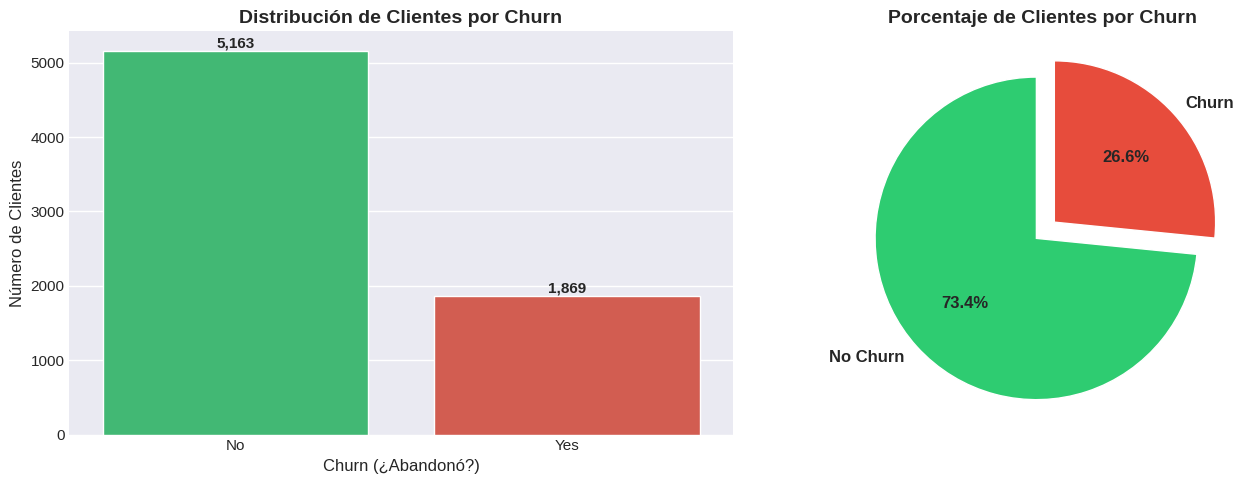

In [20]:
print("\n" + "="*60)
print("📊 ANÁLISIS DE CHURN")
print("="*60)

# Estadísticas de Churn
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print(f"\n📌 DISTRIBUCIÓN DE CHURN:")
print(f"   • Clientes que NO abandonaron: {churn_counts['No']:,} ({churn_pct['No']:.1f}%)")
print(f"   • Clientes que SÍ abandonaron: {churn_counts['Yes']:,} ({churn_pct['Yes']:.1f}%)")
print(f"\n   ⚠️ TASA DE CHURN: {churn_pct['Yes']:.1f}%")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Barras
sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#2ecc71', '#e74c3c'], order=['No', 'Yes'])
axes[0].set_title('Distribución de Clientes por Churn', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Churn (¿Abandonó?)', fontsize=12)
axes[0].set_ylabel('Número de Clientes', fontsize=12)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

# Gráfico 2: Pastel
axes[1].pie(churn_pct, labels=['No Churn', 'Churn'], autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0.05, 0.1),
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Porcentaje de Clientes por Churn', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

💸 ANÁLISIS DE INGRESOS PERDIDOS POR FUGA

📌 INGRESOS TOTALES:
   • Ingresos totales de todos los clientes: $16,056,168.70
   • Ingresos de clientes retenidos: $13,193,241.80
   • INGRESOS PERDIDOS POR FUGA: $2,862,926.90

📌 IMPACTO MENSUAL:
   • Ingresos mensuales perdidos por fuga: $139,130.85
   • Equivalente a 0.87% de los ingresos totales

💡 INTERPRETACIÓN:
   • Por cada cliente que se va, pierdes en promedio $1531.80
   • Los clientes que se van dejan de generar $139,130.85 mensuales


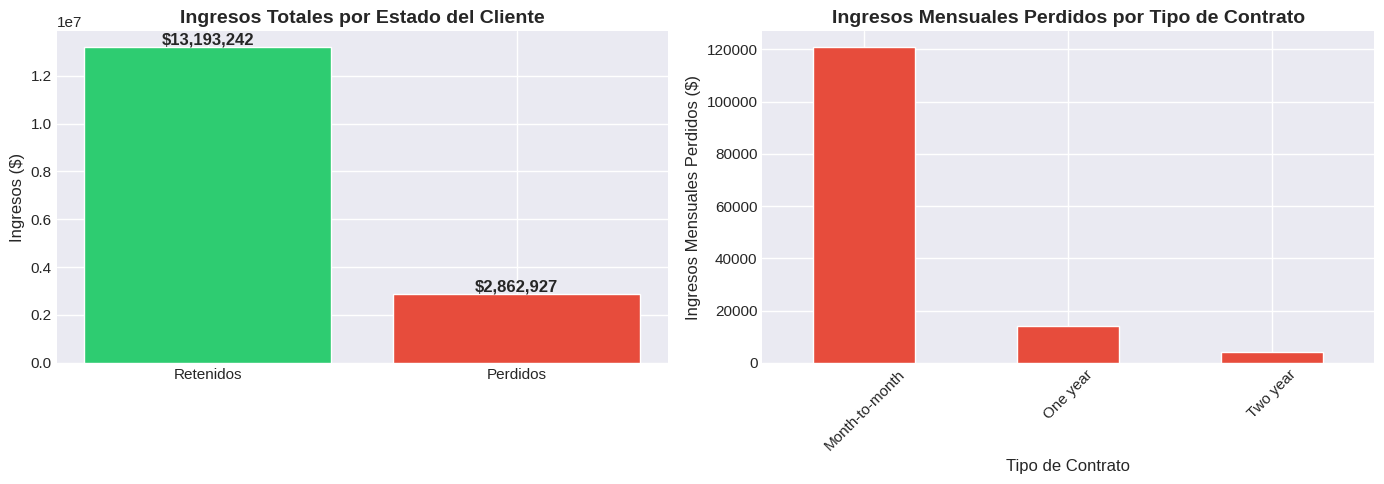

In [21]:
print("="*80)
print("💸 ANÁLISIS DE INGRESOS PERDIDOS POR FUGA")
print("="*80)

# Calcular ingresos totales y perdidos
ingresos_totales = df['TotalCharges'].sum()
ingresos_perdidos = df[df['Churn'] == 'Yes']['TotalCharges'].sum()
ingresos_retenidos = df[df['Churn'] == 'No']['TotalCharges'].sum()

# Ingresos mensuales perdidos
ingresos_mensuales_perdidos = df[df['Churn'] == 'Yes']['MonthlyCharges'].sum()

print(f"\n📌 INGRESOS TOTALES:")
print(f"   • Ingresos totales de todos los clientes: ${ingresos_totales:,.2f}")
print(f"   • Ingresos de clientes retenidos: ${ingresos_retenidos:,.2f}")
print(f"   • INGRESOS PERDIDOS POR FUGA: ${ingresos_perdidos:,.2f}")

print(f"\n📌 IMPACTO MENSUAL:")
print(f"   • Ingresos mensuales perdidos por fuga: ${ingresos_mensuales_perdidos:,.2f}")
print(f"   • Equivalente a {ingresos_mensuales_perdidos/ingresos_totales*100:.2f}% de los ingresos totales")

print(f"\n💡 INTERPRETACIÓN:")
print(f"   • Por cada cliente que se va, pierdes en promedio ${df[df['Churn']=='Yes']['TotalCharges'].mean():.2f}")
print(f"   • Los clientes que se van dejan de generar ${ingresos_mensuales_perdidos:,.2f} mensuales")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Comparación de ingresos
categorias = ['Retenidos', 'Perdidos']
valores = [ingresos_retenidos, ingresos_perdidos]
colores = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(categorias, valores, color=colores)
axes[0].set_title('Ingresos Totales por Estado del Cliente', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Ingresos ($)', fontsize=12)
for bar, val in zip(bars, valores):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                f'${val:,.0f}', ha='center', va='bottom', fontweight='bold')

# Gráfico 2: Ingresos mensuales perdidos
df_churn = df[df['Churn'] == 'Yes']
ingresos_por_contrato = df_churn.groupby('Contract')['MonthlyCharges'].sum().sort_values(ascending=False)
ingresos_por_contrato.plot(kind='bar', ax=axes[1], color='#e74c3c')
axes[1].set_title('Ingresos Mensuales Perdidos por Tipo de Contrato', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tipo de Contrato')
axes[1].set_ylabel('Ingresos Mensuales Perdidos ($)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

uscar variables y mayores insghtis

y solo es de telecomunicaciones., con varoables de genero, y tipo de servicio